# Neural Networks — Session 2: How do neural networks *learn*?

**A hands-on tutorial, Part II of II**


**Requirements:** `numpy`, `matplotlib`, `scikit-learn`, `torch`. All are preinstalled on Google Colab.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

np.random.seed(0)
plt.rcParams.update({"figure.dpi": 100, "font.size": 11})
relu = lambda z: np.maximum(0, z)

## 1. Recap: the forward pass

A fully-connected network is a composition of affine maps and element-wise nonlinearities. For a batch $X$ (one sample per row):

$$
Z^{[1]} = X W^{[1]} + \mathbf{b}^{[1]},\quad A^{[1]} = f(Z^{[1]}),\qquad
Z^{[2]} = A^{[1]} W^{[2]} + \mathbf{b}^{[2]},\quad \hat{Y} = Z^{[2]}.
$$

Here is last session's hand-built XOR network, to remind us what a forward pass looks like in code.

In [ ]:
def forward(X, params, f=relu):
    A = X
    for i, (W, b) in enumerate(params):
        Z = A @ W + b
        A = f(Z) if i < len(params) - 1 else Z
    return A

X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
params_xor = [(np.array([[1.0, 1.0], [1.0, 1.0]]), np.array([0.0, -1.0])),
              (np.array([[1.0], [-2.0]]),            np.array([0.0]))]
print("XOR network output:", forward(X_xor, params_xor).ravel(), "  (target: 0 1 1 0)")

XOR network output: [0. 1. 1. 0.]   (target: 0 1 1 0)


## 2. Loss functions: measuring "wrong"

Training means choosing the parameters $\theta$ (all weights and biases) to minimise a **loss** $\mathcal{L}(\theta)$ computed on the training data $\{(x^{(i)}, y^{(i)})\}_{i=1}^m$. For regression the standard choice is the mean squared error

$$
\mathcal{L}(\theta) = \frac{1}{m}\sum_{i=1}^m \big(\hat y^{(i)} - y^{(i)}\big)^2, \qquad \hat y^{(i)} = f(x^{(i)};\theta).
$$

For classification one uses the **cross-entropy** loss instead (Appendix B). Two things to notice:

* The loss is a function of the **parameters**, not of $x$. It is a surface over a space with as many dimensions as there are weights — thousands to billions.
* For linear regression the surface is a quadratic bowl and the minimum has a closed form (the normal equations). For a network it is **non-convex**, and we must iterate.

Let's draw the loss surface for the simplest possible model, $\hat y = wx+b$, so we can see what gradient descent is doing.

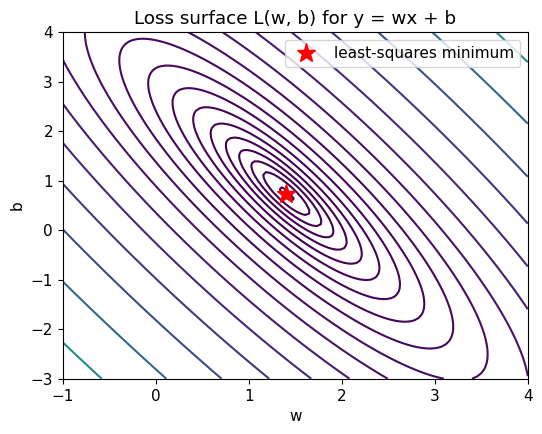

In [ ]:
# Data for a 2-parameter model y = w x + b
x_lin = np.linspace(0, 3, 40)
y_lin = 1.5 * x_lin + 0.5 + 0.3 * np.random.randn(40)

def mse_lin(w, b):
    return np.mean((w * x_lin + b - y_lin) ** 2)

wgrid, bgrid = np.meshgrid(np.linspace(-1, 4, 120), np.linspace(-3, 4, 120))
L = np.vectorize(mse_lin)(wgrid, bgrid)
w_opt, b_opt = np.polyfit(x_lin, y_lin, 1)      # closed-form least squares

plt.figure(figsize=(6, 4.5))
plt.contour(wgrid, bgrid, L, levels=np.logspace(-1, 2, 20), cmap="viridis")
plt.plot(w_opt, b_opt, "r*", ms=14, label="least-squares minimum")
plt.xlabel("w"); plt.ylabel("b"); plt.title("Loss surface L(w, b) for y = wx + b"); plt.legend(); plt.show()

## 3. Gradient descent

The gradient $\nabla_\theta \mathcal{L}$ points uphill, so we step the other way:

$$
\theta \leftarrow \theta - \alpha\, \nabla_\theta \mathcal{L}(\theta),
$$

with a **learning rate** $\alpha>0$. That is the whole algorithm. Its one knob, $\alpha$, matters enormously: too small and we crawl, too large and we overshoot and diverge.

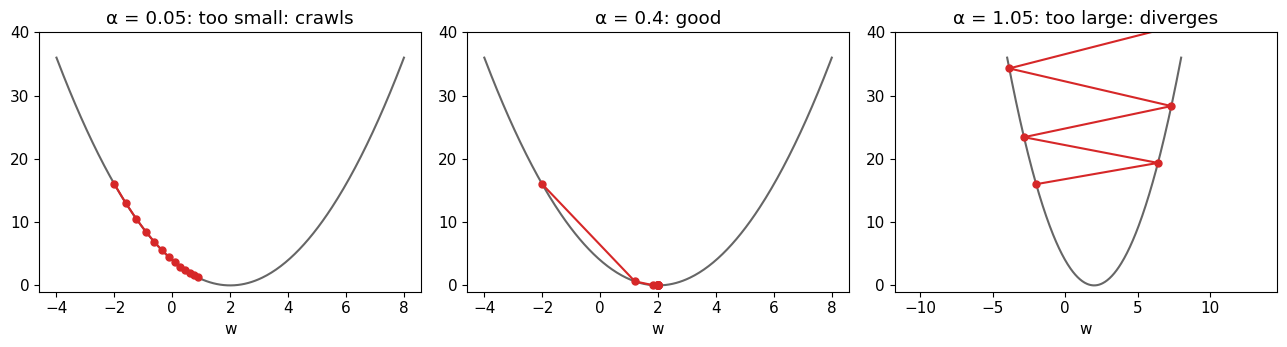

In [ ]:
# 1-D illustration: minimise L(w) = (w - 2)^2 with three learning rates
Lw = lambda w: (w - 2) ** 2
dLw = lambda w: 2 * (w - 2)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, lr, title in zip(axes, [0.05, 0.4, 1.05], ["too small: crawls", "good", "too large: diverges"]):
    w = -2.0; path = [w]
    for _ in range(12):
        w = w - lr * dLw(w); path.append(w)
    path = np.array(path)
    ws = np.linspace(-4, 8, 300)
    ax.plot(ws, Lw(ws), "k", alpha=0.6)
    ax.plot(path, Lw(path), "o-", color="C3", ms=5)
    ax.set_title(f"α = {lr}: {title}"); ax.set_xlabel("w"); ax.set_ylim(-1, 40)
plt.tight_layout(); plt.show()

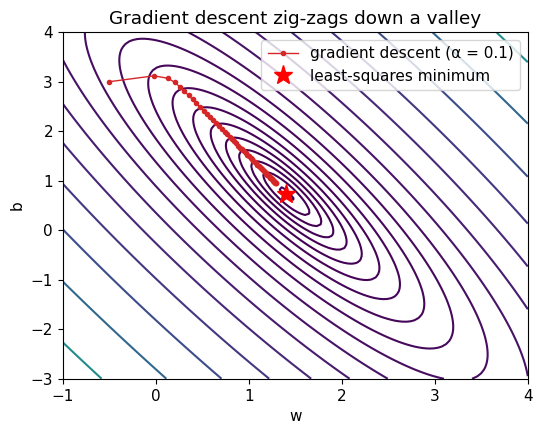

In [ ]:
# 2-D: gradient descent on the loss surface from Section 2
def grad_mse_lin(w, b):
    r = w * x_lin + b - y_lin
    return np.array([2 * np.mean(r * x_lin), 2 * np.mean(r)])

theta = np.array([-0.5, 3.0]); path = [theta.copy()]
for _ in range(60):
    theta = theta - 0.1 * grad_mse_lin(*theta); path.append(theta.copy())
path = np.array(path)

plt.figure(figsize=(6, 4.5))
plt.contour(wgrid, bgrid, L, levels=np.logspace(-1, 2, 20), cmap="viridis")
plt.plot(path[:, 0], path[:, 1], "o-", color="C3", ms=3, lw=1, label="gradient descent (α = 0.1)")
plt.plot(w_opt, b_opt, "r*", ms=14, label="least-squares minimum")
plt.xlabel("w"); plt.ylabel("b"); plt.legend(); plt.title("Gradient descent zig-zags down a valley")
plt.show()

The zig-zag is the familiar effect of **ill-conditioning**: the valley is long in one direction and narrow in another, exactly as in your conjugate-gradient intuition. In practice three refinements are universal:

* **Stochastic / mini-batch** gradient descent — evaluate the gradient on a random subset of the data at each step. Cheaper, and the noise even helps escape poor regions.
* **Momentum** — average successive gradients, which damps the zig-zag.
* **Adam** — momentum plus a per-parameter adaptive step size. It is the default optimiser in most of deep learning and we use it below.

None of these change the picture: *follow the negative gradient, in small steps, many times.*

## 4. Backpropagation: getting the gradient cheaply

We need $\partial\mathcal{L}/\partial\theta$ for *every* weight. Finite differences would cost one forward pass per parameter — hopeless for a million parameters. **Backpropagation** is the chain rule applied layer by layer from the output backwards; it delivers *all* gradients for roughly the cost of two forward passes, independent of the number of parameters. (In automatic-differentiation language: reverse mode.)

For our 2-layer network with MSE loss, writing $\delta^{[2]} = \partial \mathcal{L}/\partial Z^{[2]} = \frac{2}{m}(\hat Y - Y)$:

$$
\frac{\partial \mathcal{L}}{\partial W^{[2]}} = (A^{[1]})^\top \delta^{[2]},\qquad
\frac{\partial \mathcal{L}}{\partial \mathbf{b}^{[2]}} = \textstyle\sum_{\text{rows}} \delta^{[2]},
$$

$$
\delta^{[1]} = \big(\delta^{[2]} (W^{[2]})^\top\big) \odot \mathrm{ReLU}'(Z^{[1]}),\qquad
\frac{\partial \mathcal{L}}{\partial W^{[1]}} = X^\top \delta^{[1]},\qquad
\frac{\partial \mathcal{L}}{\partial \mathbf{b}^{[1]}} = \textstyle\sum_{\text{rows}} \delta^{[1]} .
$$

Each line is one application of the chain rule; the full derivation is in Appendix A. The *pattern* is what matters: an error signal $\delta$ flows backwards through the network, and each layer's gradient is "its input, transposed, times the $\delta$ arriving from above."

Rather than trust the algebra, let's **check it against finite differences** — a gradient check is the first thing any numerical analyst would do, and it catches most bugs in hand-written backprop.

In [ ]:
def forward_backward(X, Y, W1, b1, W2, b2):
    '''Forward pass + backpropagation for a 2-layer ReLU network with MSE loss.
    Returns loss and the four gradients.'''
    m = X.shape[0]
    Z1 = X @ W1 + b1;  A1 = relu(Z1)
    Z2 = A1 @ W2 + b2; Yhat = Z2
    loss = np.mean((Yhat - Y) ** 2)
    # backward
    d2 = 2 * (Yhat - Y) / m                      # dL/dZ2
    dW2 = A1.T @ d2;  db2 = d2.sum(axis=0, keepdims=True)
    d1 = (d2 @ W2.T) * (Z1 > 0)                  # dL/dZ1  (ReLU' = indicator)
    dW1 = X.T @ d1;   db1 = d1.sum(axis=0, keepdims=True)
    return loss, (dW1, db1, dW2, db2)

# Gradient check on a tiny network
rng = np.random.default_rng(0)
Xc, Yc = rng.normal(size=(5, 3)), rng.normal(size=(5, 1))
W1c, b1c = rng.normal(size=(3, 4)), rng.normal(size=(1, 4))
W2c, b2c = rng.normal(size=(4, 1)), rng.normal(size=(1, 1))
loss, grads = forward_backward(Xc, Yc, W1c, b1c, W2c, b2c)

eps = 1e-6
for name, P, G in zip(["W1", "b1", "W2", "b2"], [W1c, b1c, W2c, b2c], grads):
    G_fd = np.zeros_like(P)
    for idx in np.ndindex(P.shape):
        P[idx] += eps; lp = forward_backward(Xc, Yc, W1c, b1c, W2c, b2c)[0]
        P[idx] -= 2 * eps; lm = forward_backward(Xc, Yc, W1c, b1c, W2c, b2c)[0]
        P[idx] += eps
        G_fd[idx] = (lp - lm) / (2 * eps)
    print(f"{name}: max |backprop - finite difference| = {np.abs(G - G_fd).max():.2e}")

W1: max |backprop - finite difference| = 1.06e-10
b1: max |backprop - finite difference| = 7.10e-11
W2: max |backprop - finite difference| = 1.39e-10
b2: max |backprop - finite difference| = 2.24e-11


## 5. Training a network from scratch in NumPy

Now the whole loop: **forward pass → loss → backward pass → gradient step, repeat.** We fit $y=\sin(x)$ from noisy samples with a 1→30→1 ReLU network, and save snapshots so we can *watch* the fit emerge.

trained for 10000 epochs in 0.9 s; final loss = 0.0100


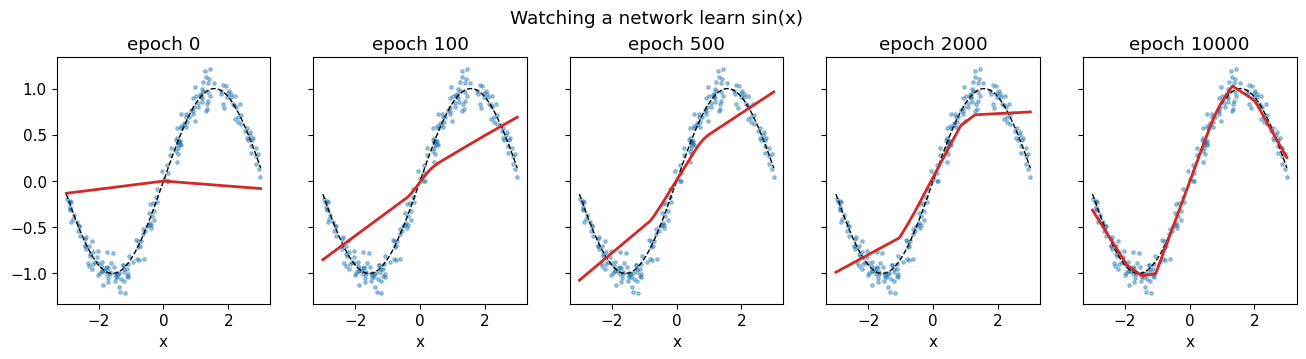

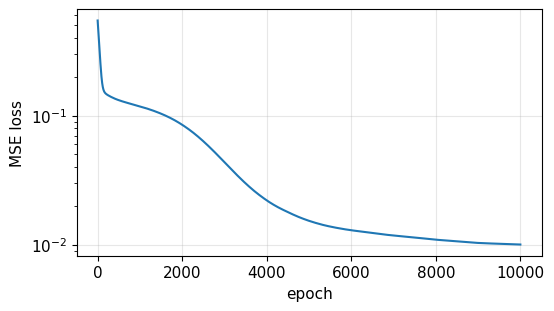

In [ ]:
# Data
m = 200
X = np.random.uniform(-3, 3, size=(m, 1))
Y = np.sin(X) + 0.1 * np.random.randn(m, 1)
X_plot = np.linspace(-3, 3, 300)[:, None]

# Initialise a 1 -> 30 -> 1 network
hidden = 30
W1 = 0.1 * np.random.randn(1, hidden); b1 = np.zeros((1, hidden))
W2 = 0.1 * np.random.randn(hidden, 1); b2 = np.zeros((1, 1))

lr, epochs = 0.01, 10000
snapshots_at = [0, 100, 500, 2000, 10000]
snapshots, losses = {}, []

t0 = time.perf_counter()
for epoch in range(epochs + 1):
    loss, (dW1, db1, dW2, db2) = forward_backward(X, Y, W1, b1, W2, b2)
    losses.append(loss)
    if epoch in snapshots_at:
        snapshots[epoch] = forward(X_plot, [(W1, b1), (W2, b2)]).copy()
    # gradient descent step
    W1 -= lr * dW1; b1 -= lr * db1; W2 -= lr * dW2; b2 -= lr * db2
print(f"trained for {epochs} epochs in {time.perf_counter() - t0:.1f} s; final loss = {losses[-1]:.4f}")

fig, axes = plt.subplots(1, len(snapshots_at), figsize=(16, 3.2), sharey=True)
for ax, ep in zip(axes, snapshots_at):
    ax.scatter(X, Y, s=6, alpha=0.4); ax.plot(X_plot, np.sin(X_plot), "k--", lw=1)
    ax.plot(X_plot, snapshots[ep], "C3", lw=2); ax.set_title(f"epoch {ep}"); ax.set_xlabel("x")
plt.suptitle("Watching a network learn sin(x)", y=1.03); plt.show()

plt.figure(figsize=(6, 3.2)); plt.semilogy(losses); plt.xlabel("epoch"); plt.ylabel("MSE loss"); plt.grid(alpha=0.3); plt.show()

That is **all** a neural network is: forty lines of NumPy. The network starts as a flat line (small random weights), the kinks of the ReLUs move to where the data needs them, and the loss keeps falling. No magic anywhere — matrix products and the chain rule.

## 6. The same thing in PyTorch

A deep-learning framework gives you three things:

1. **Automatic differentiation.** You write only the forward pass; `loss.backward()` performs backpropagation for *any* computation graph. No hand-derived gradients, no gradient checks.
2. **Optimisers** (SGD, Adam, …) and standard layers/losses.
3. **GPU execution** with a one-line change (`.to("cuda")`).

Below is the previous example again. Compare the training loop to the NumPy one: the four hand-written gradient lines have become `loss.backward()`.

PyTorch 2.14.1+cu130 | device: cpu


2000 epochs in 1.8 s; final loss = 0.0086


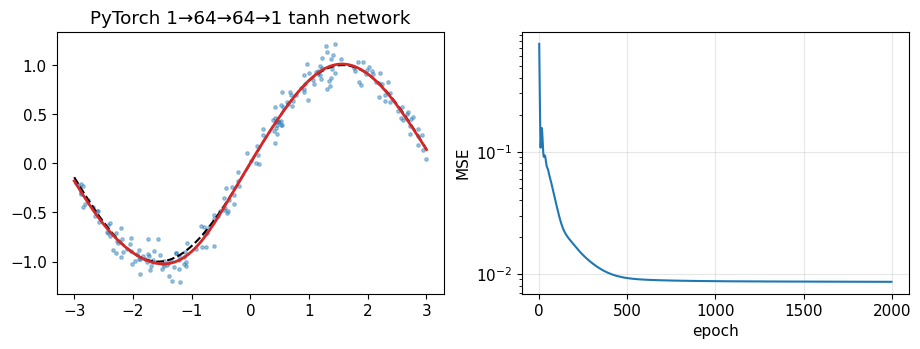

In [ ]:
import torch
import torch.nn as nn

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

Xt = torch.tensor(X, dtype=torch.float32)        # reuse the NumPy data from Section 5
Yt = torch.tensor(Y, dtype=torch.float32)

model = nn.Sequential(nn.Linear(1, 64), nn.Tanh(),
                      nn.Linear(64, 64), nn.Tanh(),
                      nn.Linear(64, 1))
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

t0 = time.perf_counter(); torch_losses = []
for epoch in range(2000):
    optimizer.zero_grad()               # clear old gradients
    loss = loss_fn(model(Xt), Yt)       # forward pass + loss
    loss.backward()                     # backpropagation (automatic!)
    optimizer.step()                    # gradient step (Adam)
    torch_losses.append(loss.item())
print(f"2000 epochs in {time.perf_counter() - t0:.1f} s; final loss = {torch_losses[-1]:.4f}")

with torch.no_grad():
    y_pred = model(torch.tensor(X_plot, dtype=torch.float32)).numpy()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].scatter(X, Y, s=6, alpha=0.4); axes[0].plot(X_plot, np.sin(X_plot), "k--"); axes[0].plot(X_plot, y_pred, "C3", lw=2)
axes[0].set_title("PyTorch 1→64→64→1 tanh network")
axes[1].semilogy(torch_losses); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("MSE"); axes[1].grid(alpha=0.3)
plt.show()

### 6.1 Classification: recognising handwritten digits

Everything so far was regression. For classification the only changes are: the output layer has one neuron per class, and the loss is **cross-entropy** on softmax probabilities (Appendix B). PyTorch's `nn.CrossEntropyLoss` does both.

We use `scikit-learn`'s built-in 8×8 digit images (1 797 samples, no download needed). Appendix C has the same code for the classic 28×28 MNIST set (60 000 images, needs an internet download).

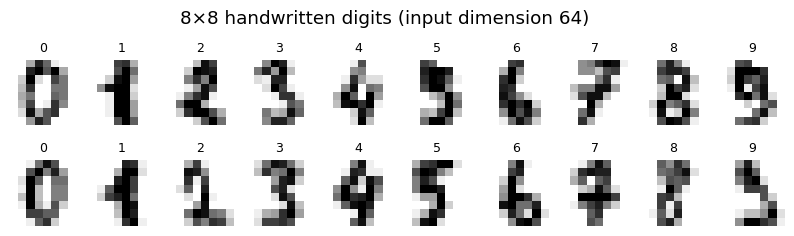

epoch   0  train loss 2.324  test accuracy 10.0%
epoch 100  train loss 0.770  test accuracy 90.4%


epoch 200  train loss 0.247  test accuracy 94.4%
epoch 299  train loss 0.141  test accuracy 96.7%


In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
Xd, yd = digits.data / 16.0, digits.target                 # scale pixels to [0, 1]
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.25, random_state=0)

fig, axes = plt.subplots(2, 10, figsize=(10, 2.4))
for ax, img, lab in zip(axes.flat, digits.images, digits.target):
    ax.imshow(img, cmap="gray_r"); ax.set_title(lab, fontsize=9); ax.axis("off")
plt.suptitle("8×8 handwritten digits (input dimension 64)", y=1.05); plt.show()

to_t = lambda a, dt=torch.float32: torch.tensor(a, dtype=dt)
Xtr, ytr, Xte, yte = to_t(Xd_tr), to_t(yd_tr, torch.long), to_t(Xd_te), to_t(yd_te, torch.long)

clf = nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 10))   # 10 outputs = 10 classes
opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
ce = nn.CrossEntropyLoss()

for epoch in range(300):
    opt.zero_grad(); loss = ce(clf(Xtr), ytr); loss.backward(); opt.step()
    if epoch % 100 == 0 or epoch == 299:
        with torch.no_grad():
            acc = (clf(Xte).argmax(1) == yte).float().mean().item()
        print(f"epoch {epoch:3d}  train loss {loss.item():.3f}  test accuracy {100*acc:.1f}%")

15 of 450 test digits misclassified


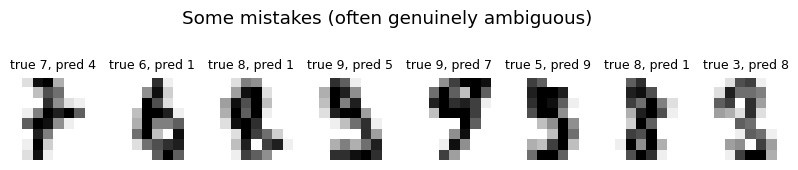

In [ ]:
with torch.no_grad():
    pred = clf(Xte).argmax(1).numpy()
wrong = np.where(pred != yd_te)[0]
print(f"{len(wrong)} of {len(yd_te)} test digits misclassified")

fig, axes = plt.subplots(1, min(8, len(wrong)), figsize=(10, 1.8))
for ax, i in zip(np.atleast_1d(axes), wrong[:8]):
    ax.imshow(Xd_te[i].reshape(8, 8), cmap="gray_r"); ax.set_title(f"true {yd_te[i]}, pred {pred[i]}", fontsize=9); ax.axis("off")
plt.suptitle("Some mistakes (often genuinely ambiguous)", y=1.1); plt.show()

## 7. Practical realities

### 7.1 Overfitting

A flexible model can fit the *noise*. Watch the loss on held-out test data: it falls, then **rises** while the training loss keeps falling. Here a 1→100→100→1 network is trained on only 25 noisy points.

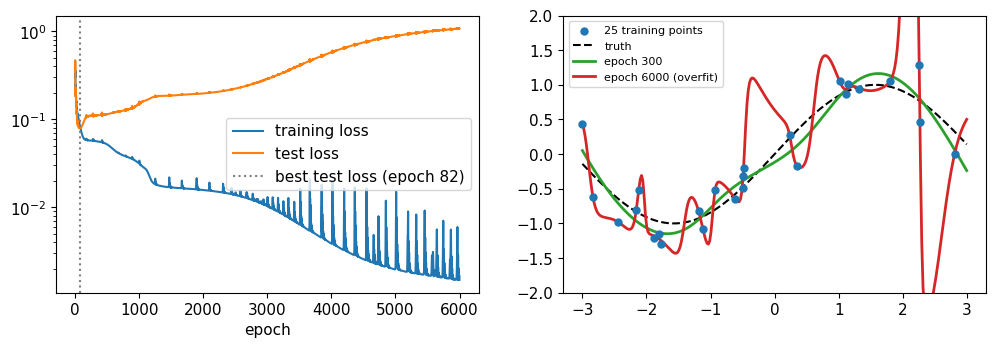

In [ ]:
torch.manual_seed(1); np.random.seed(1)
xs_small = np.random.uniform(-3, 3, (25, 1)); ys_small = np.sin(xs_small) + 0.3 * np.random.randn(25, 1)
xs_test = np.random.uniform(-3, 3, (200, 1)); ys_test = np.sin(xs_test) + 0.3 * np.random.randn(200, 1)
Xs, Ys, Xtest, Ytest = map(to_t, (xs_small, ys_small, xs_test, ys_test))

big = nn.Sequential(nn.Linear(1, 100), nn.Tanh(), nn.Linear(100, 100), nn.Tanh(), nn.Linear(100, 1))
opt = torch.optim.Adam(big.parameters(), lr=3e-3)
tr_loss, te_loss, fits = [], [], {}
for epoch in range(6000):
    opt.zero_grad(); l = loss_fn(big(Xs), Ys); l.backward(); opt.step()
    with torch.no_grad():
        tr_loss.append(l.item()); te_loss.append(loss_fn(big(Xtest), Ytest).item())
        if epoch in (300, 5999):
            fits[epoch] = big(torch.tensor(X_plot, dtype=torch.float32)).numpy()
best = int(np.argmin(te_loss))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].semilogy(tr_loss, label="training loss"); axes[0].semilogy(te_loss, label="test loss")
axes[0].axvline(best, color="gray", ls=":", label=f"best test loss (epoch {best})"); axes[0].legend(); axes[0].set_xlabel("epoch")
axes[1].scatter(xs_small, ys_small, s=25, zorder=3, label="25 training points"); axes[1].plot(X_plot, np.sin(X_plot), "k--", label="truth")
axes[1].plot(X_plot, fits[300], "C2", lw=2, label="epoch 300"); axes[1].plot(X_plot, fits[5999], "C3", lw=2, label="epoch 6000 (overfit)")
axes[1].legend(fontsize=8); axes[1].set_ylim(-2, 2)
plt.show()

The usual remedies: **more data**, **early stopping** (keep the parameters from the best test-loss epoch — a validation set is essential), **a smaller network**, **weight decay** (an $\ell_2$ penalty on the weights — Tikhonov regularisation), and **dropout** (randomly silencing neurons during training).

### 7.2 What you actually tune

| group | hyperparameters |
|---|---|
| architecture | width, depth, activation (tanh for smooth problems, ReLU for most others) |
| optimisation | learning rate (the most important one), batch size, number of epochs, optimiser (Adam) |
| regularisation | weight decay, dropout, early stopping |
| data | **scale your inputs and outputs** to order one — unscaled data is the most common reason a network "doesn't train" |

### 7.3 When *not* to use a neural network

Neural networks shine with large amounts of data, high-dimensional inputs (images, text, many sensors), and no good hand-crafted model. They are usually the wrong tool for:

* small tabular data sets (a few hundred rows) — gradient-boosted trees or classical statistics usually win;
* problems where you need interpretability, error bounds, or guarantees;
* low-dimensional smooth problems that a classical method already solves well.

A trained network is a function with thousands of parameters chosen by a heuristic optimiser: a powerful fitting tool, not a model of the world.

## 8. Beyond the basics

Everything in this tutorial was a *fully-connected* network. The famous architectures are variations that bake in structure:

* **Convolutional networks (CNNs)** — for images: each neuron looks at a small patch and the same weights are reused across the image (translation invariance). Parameters drop from millions to thousands per layer.
* **Recurrent networks (RNNs/LSTMs)** — for sequences: the network is applied step by step and carries a hidden state.
* **Transformers** — for sequences, now also images: an *attention* mechanism lets every element of the input look at every other. Large language models (GPT, Claude, …) are transformers with $10^{11}$ – $10^{12}$ parameters, trained with exactly the loop of Section 5 (cross-entropy loss, Adam, backpropagation) on trillions of words.
* **Physics-informed networks (PINNs)** — the network $u_\theta(x,t)$ is a candidate PDE solution and the loss is the PDE residual at sample points, computed by automatic differentiation. We will see one in the demo sessions.

### Where to go next

* 3Blue1Brown, *Neural networks* (YouTube series) — the best visual explanation of backpropagation.
* Michael Nielsen, *Neural Networks and Deep Learning* (free online book) — short, mathematical, with code.
* Andrej Karpathy, *Neural Networks: Zero to Hero* (YouTube) — builds autograd and GPT from scratch.
* [playground.tensorflow.org](https://playground.tensorflow.org) — interactive, no installation.
* PyTorch tutorials: [pytorch.org/tutorials](https://pytorch.org/tutorials).

---
## Appendix A. Backpropagation for a 2-layer network, in full

**Network.** Input $X\in\mathbb{R}^{m\times n_{\rm in}}$ (one sample per row), hidden layer with ReLU, linear output:

$$
Z^{[1]} = X W^{[1]} + \mathbf{b}^{[1]},\qquad A^{[1]} = \mathrm{ReLU}(Z^{[1]}) = \max(0, Z^{[1]}),\qquad
Z^{[2]} = A^{[1]} W^{[2]} + \mathbf{b}^{[2]},\qquad \hat{Y} = Z^{[2]} .
$$

**Loss.** $\mathcal{L} = \frac{1}{m}\sum_{i=1}^m \big(\hat y^{(i)} - y^{(i)}\big)^2 .$

**Output layer.** Differentiate the loss with respect to the output pre-activation:

$$
\frac{\partial \mathcal{L}}{\partial Z^{[2]}} = \frac{2}{m}\big(Z^{[2]} - Y\big) =: \delta^{[2]} .
$$

Since $Z^{[2]} = A^{[1]} W^{[2]} + \mathbf{b}^{[2]}$ is linear in $W^{[2]}$ and $\mathbf{b}^{[2]}$, the chain rule gives

$$
\frac{\partial \mathcal{L}}{\partial W^{[2]}} = (A^{[1]})^\top \delta^{[2]},\qquad
\frac{\partial \mathcal{L}}{\partial \mathbf{b}^{[2]}} = \sum_{i=1}^m \delta^{[2]}_{i,:} .
$$

**Hidden layer.** Propagate the error signal backwards through $W^{[2]}$ and then through the activation:

$$
\frac{\partial \mathcal{L}}{\partial A^{[1]}} = \delta^{[2]} (W^{[2]})^\top,\qquad
\delta^{[1]} := \frac{\partial \mathcal{L}}{\partial Z^{[1]}} = \frac{\partial \mathcal{L}}{\partial A^{[1]}} \odot \mathrm{ReLU}'(Z^{[1]}),\qquad
\mathrm{ReLU}'(z) = \begin{cases} 1 & z>0 \\ 0 & z\le 0 \end{cases}
$$

($\odot$ is the element-wise product.) Then, exactly as for the output layer,

$$
\frac{\partial \mathcal{L}}{\partial W^{[1]}} = X^\top \delta^{[1]},\qquad
\frac{\partial \mathcal{L}}{\partial \mathbf{b}^{[1]}} = \sum_{i=1}^m \delta^{[1]}_{i,:} .
$$

**Update.** With learning rate $\alpha$: $\;W^{[\ell]} \leftarrow W^{[\ell]} - \alpha\, \partial\mathcal{L}/\partial W^{[\ell]}$ and likewise for $\mathbf{b}^{[\ell]}$, $\ell=1,2$.

**The general pattern.** For a network with any number of layers, $\delta^{[\ell]} = \big(\delta^{[\ell+1]} (W^{[\ell+1]})^\top\big) \odot f'(Z^{[\ell]})$ and $\partial\mathcal{L}/\partial W^{[\ell]} = (A^{[\ell-1]})^\top \delta^{[\ell]}$. One matrix product per layer, backwards — hence *back*-propagation. This is precisely what `loss.backward()` executes in PyTorch, for arbitrary computation graphs.

## Appendix B. Cross-entropy loss for classification

For $C$ classes the network outputs $C$ real numbers (**logits**) $z_1,\dots,z_C$, converted to probabilities by the **softmax**

$$
\hat y_c = \frac{e^{z_c}}{\sum_{k=1}^C e^{z_k}} .
$$

The **cross-entropy** loss compares these with the true labels (one-hot encoded, $y_{i,c}\in\{0,1\}$):

$$
\mathcal{L} = -\frac{1}{N}\sum_{i=1}^N \sum_{c=1}^C y_{i,c}\,\log \hat y_{i,c}
            = -\frac{1}{N}\sum_{i=1}^N \log \hat y_{i,c^*_i},
$$

i.e. minus the average log-probability assigned to the correct class $c^*_i$. It is the negative log-likelihood of the data under the model, heavily penalises confident mistakes, and for two classes reduces to the familiar logistic-regression loss $-\frac1N\sum_i \big[y_i\log\hat y_i + (1-y_i)\log(1-\hat y_i)\big]$. PyTorch's `nn.CrossEntropyLoss` takes the raw logits and applies softmax internally (numerically safer).

In [ ]:
# Cross-entropy on three samples with four classes
logits = torch.tensor([[2.0, 1.0, 0.1, -1.0],
                       [0.5, 2.5, 3.0,  1.5],
                       [4.0, 0.2, 1.2,  3.3]])
labels = torch.tensor([1, 2, 0])
probs = torch.softmax(logits, dim=1)
print("softmax probabilities:\n", probs.numpy().round(3))
print("cross-entropy loss:", nn.CrossEntropyLoss()(logits, labels).item())
print("check: -mean(log p[true class]) =", (-torch.log(probs[range(3), labels])).mean().item())

softmax probabilities:
 [[0.638 0.235 0.095 0.032]
 [0.043 0.317 0.523 0.117]
 [0.633 0.014 0.038 0.314]]
cross-entropy loss: 0.8515355587005615
check: -mean(log p[true class]) = 0.8515354990959167


## Appendix C. The classic MNIST example (28×28 digits, 60 000 images)

Same model, same loop, bigger data. This downloads MNIST through `torchvision` (≈ 10 MB) the first time, so it is switched off by default; set `RUN_MNIST = True` to run it (≈ 1 min on Colab). It trains in mini-batches of 64 — the standard practice for large data sets.

In [ ]:
RUN_MNIST = False

if RUN_MNIST:
    from torchvision import datasets, transforms
    from torch.utils.data import DataLoader

    tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
    train_ds = datasets.MNIST(root="./datasets", train=True, transform=tf, download=True)
    test_ds = datasets.MNIST(root="./datasets", train=False, transform=tf, download=True)
    train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
    test_loader = DataLoader(test_ds, batch_size=256)

    mnist_model = nn.Sequential(nn.Flatten(), nn.Linear(28 * 28, 128), nn.ReLU(), nn.Linear(128, 10)).to(device)
    opt = torch.optim.Adam(mnist_model.parameters(), lr=1e-3)
    for epoch in range(3):
        for images, labels in train_loader:                       # mini-batch training
            images, labels = images.to(device), labels.to(device)
            opt.zero_grad(); loss = ce(mnist_model(images), labels); loss.backward(); opt.step()
        correct = sum((mnist_model(im.to(device)).argmax(1).cpu() == lb).sum().item() for im, lb in test_loader)
        print(f"epoch {epoch+1}: test accuracy {100 * correct / len(test_ds):.2f}%")

    images, labels = next(iter(test_loader))
    preds = mnist_model(images.to(device)).argmax(1).cpu()
    fig, axes = plt.subplots(1, 8, figsize=(10, 1.8))
    for ax, im, lb, pr in zip(axes, images, labels, preds):
        ax.imshow(im.squeeze(), cmap="gray"); ax.set_title(f"true {lb.item()}, pred {pr.item()}", fontsize=8); ax.axis("off")
    plt.show()
else:
    print("MNIST example skipped (set RUN_MNIST = True to run; requires internet access).")

MNIST example skipped (set RUN_MNIST = True to run; requires internet access).
